# 20 — OLID-I Feature Importance & Ablation

**Investigating whether all 38 handcrafted features contribute meaningfully to the OLID-I 57-class plant-stress classification task, identifying redundancy, and analyzing predictive stability.**

---

## 1. Objective & Research Questions
NB18 established a strong flat baseline using a Random Forest on all 38 features (Macro-F1 ≈ 0.550). 
This notebook analyzes:
1. Are all 38 features useful?
2. Which feature groups contribute the most?
3. Which individual features are consistently important?
4. Which features appear redundant?
5. Are any features potentially harmful?
6. How many features are needed to approach the performance of all 38?
7. Does a reduced feature subset outperform or match the full 38-feature Random Forest?
8. What does this imply for the 38-node graph design?

**CRITICAL LEAKAGE RULE:** All feature evaluations and selections are performed using validation-fold permutation importance and training-fold-only statistics.


## 2. Dataset Loading

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
N_FOLDS      = 5
RESULTS_DIR  = 'results/feature_analysis'
os.makedirs(RESULTS_DIR, exist_ok=True)

csv_path = '../olid_full_features.csv'
df_full  = pd.read_csv(csv_path)
df_accepted = df_full[df_full['quality_flag'] == 'ACCEPT'].copy().reset_index(drop=True)

meta_cols = ['image_path', 'image_name', 'class', 'crop', 'condition',
             'quality_flag', 'mask_area_ratio', 'failure_reason']
feature_cols = [c for c in df_accepted.columns if c not in meta_cols]

assert len(df_accepted) == 4387
assert len(feature_cols) == 38

print(f"Accepted images: {len(df_accepted)}")
print(f"Features: {len(feature_cols)}")

df_folds = pd.read_csv('../cv_fold_assignments.csv')
df_accepted = df_accepted.merge(df_folds[['image_path', 'fold']], on='image_path', how='left')
assert df_accepted['fold'].isna().sum() == 0, "Missing fold assignments!"


Accepted images: 4387
Features: 38


In [2]:
FEATURE_GROUPS = {
    'Shape': ['area', 'perimeter', 'aspect_ratio', 'circularity', 'extent', 'solidity', 'convex_area', 'major_axis_length', 'minor_axis_length', 'eccentricity'],
    'RGB': ['mean_R', 'std_R', 'mean_G', 'std_G', 'mean_B', 'std_B'],
    'HSV': ['mean_H', 'std_H', 'mean_S', 'std_S', 'mean_V', 'std_V'],
    'Lab': ['mean_L', 'std_L', 'mean_a', 'std_a', 'mean_b', 'std_b'],
    'Derived Color': ['green_ratio', 'yellow_ratio'],
    'Texture': ['glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation'],
    'Spatial': ['core_mean_H', 'core_yellow_ratio', 'edge_mean_H', 'edge_yellow_ratio']
}

def get_group(feature_name):
    for g, feats in FEATURE_GROUPS.items():
        if feature_name in feats:
            return g
    return "Unknown"

class FoldSafeScaler:
    def __init__(self):
        self._scaler = StandardScaler()
        self.is_fitted = False
    def fit_transform(self, X_train):
        self.is_fitted = True
        return self._scaler.fit_transform(X_train)
    def transform(self, X_val):
        assert self.is_fitted
        return self._scaler.transform(X_val)

def get_base_model():
    return RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1)


## 3. Feature Validation

In [3]:
val_rows = []
for f in feature_cols:
    s = df_accepted[f]
    mean_v = s.mean()
    std_v = s.std()
    val_rows.append({
        'Feature': f,
        'Group': get_group(f),
        'Missing': s.isna().sum(),
        'Unique': s.nunique(),
        'Mean': mean_v,
        'Std': std_v,
        'Min': s.min(),
        'Max': s.max(),
        'Constant?': s.nunique() == 1,
        'Near-zero variance?': std_v < 1e-5
    })
df_val = pd.DataFrame(val_rows)
df_val.to_csv(f'{RESULTS_DIR}/feature_quality.csv', index=False)

print("Feature Validation Summary:")
print(f"Constant features: {df_val['Constant?'].sum()}")
print(f"Near-zero variance features: {df_val['Near-zero variance?'].sum()}")
print(f"Missing values total: {df_val['Missing'].sum()}")
print("\nTABLE A: Feature Quality (First 10 shown)")
print(df_val.head(10).to_string(index=False))


Feature Validation Summary:
Constant features: 0
Near-zero variance features: 0
Missing values total: 0

TABLE A: Feature Quality (First 10 shown)
          Feature Group  Missing  Unique         Mean          Std           Min          Max  Constant?  Near-zero variance?
             area Shape        0    4376 2.218729e+06 1.350108e+06  90675.500000 8.852678e+06      False                False
        perimeter Shape        0    4379 1.086565e+04 5.145784e+03   2188.701784 4.755636e+04      False                False
     aspect_ratio Shape        0    4328 9.504347e-01 2.251235e-01      0.317371 2.613540e+00      False                False
      circularity Shape        0    4379 2.861789e-01 1.477374e-01      0.011338 7.236222e-01      False                False
           extent Shape        0    4379 5.694819e-01 9.370828e-02      0.173385 9.680796e-01      False                False
         solidity Shape        0    4379 8.119857e-01 1.023578e-01      0.307005 9.869797e-01    

## 4. Feature Correlation / Redundancy

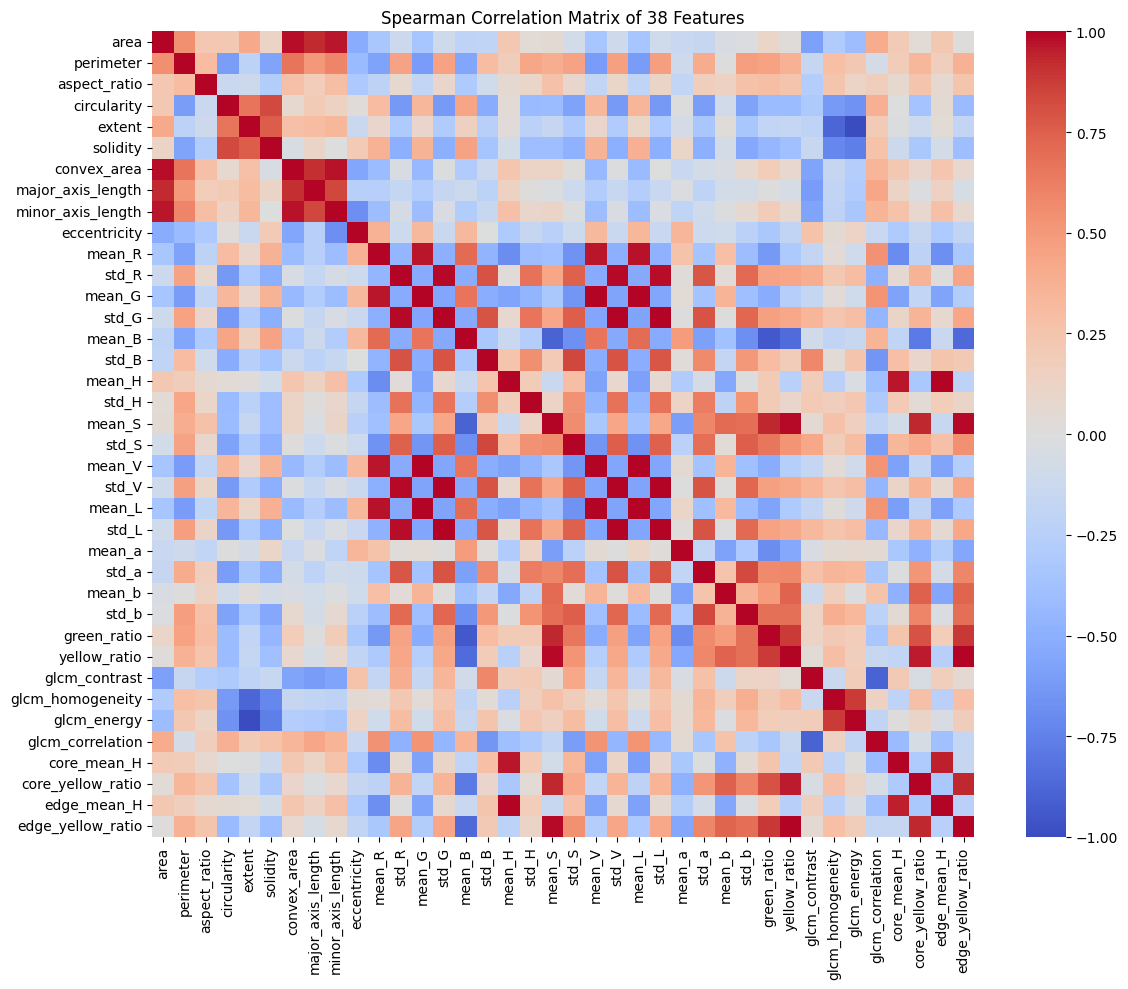

Highly Correlated Feature Pairs (|rho| >= 0.90):
        Feature 1         Feature 2  Spearman Rho
           extent       glcm_energy     -0.999854
            std_G             std_V      0.999708
           mean_G            mean_V      0.999516
            std_G             std_L      0.998629
            std_V             std_L      0.998578
           mean_H       edge_mean_H      0.998161
     yellow_ratio edge_yellow_ratio      0.998008
           mean_V            mean_L      0.997466
           mean_G            mean_L      0.997323
           mean_S edge_yellow_ratio      0.991912
           mean_S      yellow_ratio      0.991672
            std_R             std_V      0.986998
            std_R             std_G      0.986204
            std_R             std_L      0.984016
             area       convex_area      0.979767
           mean_R            mean_L      0.976509
      convex_area minor_axis_length      0.974292
           mean_H       core_mean_H      0.968225
 

In [4]:
corr_matrix = df_accepted[feature_cols].corr(method='spearman')
corr_matrix.to_csv(f'{RESULTS_DIR}/feature_correlation.csv')

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation Matrix of 38 Features")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/feature_correlation_heatmap.png")
plt.show()

# Find high correlations
high_corr = []
for i in range(len(feature_cols)):
    for j in range(i+1, len(feature_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) >= 0.90:
            high_corr.append({'Feature 1': feature_cols[i], 'Feature 2': feature_cols[j], 'Spearman Rho': r})

df_high_corr = pd.DataFrame(high_corr).sort_values(by='Spearman Rho', key=abs, ascending=False)
print("Highly Correlated Feature Pairs (|rho| >= 0.90):")
if len(df_high_corr) > 0:
    print(df_high_corr.to_string(index=False))
else:
    print("None found above threshold.")


## 5. Univariate Discriminative Analysis (Training Folds Only)

In [5]:
# Calculate MI and ANOVA F across all 5 folds using ONLY training data
univar_records = []
for fold_id in range(N_FOLDS):
    tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
    X_tr = df_accepted.loc[tr_idx, feature_cols].values
    y_tr = df_accepted.loc[tr_idx, 'class'].values
    
    # Scale first
    X_tr_sc = FoldSafeScaler().fit_transform(X_tr)
    
    mi = mutual_info_classif(X_tr_sc, y_tr, random_state=RANDOM_STATE)
    f_stat, _ = f_classif(X_tr_sc, y_tr)
    
    for i, f in enumerate(feature_cols):
        univar_records.append({
            'Fold': fold_id, 'Feature': f, 'Group': get_group(f),
            'MI': mi[i], 'ANOVA_F': f_stat[i]
        })

df_univar = pd.DataFrame(univar_records)
univar_summary = df_univar.groupby(['Feature', 'Group']).agg({
    'MI': ['mean', 'std'], 'ANOVA_F': ['mean', 'std']
}).reset_index()

univar_summary.columns = ['Feature', 'Group', 'MI_Mean', 'MI_Std', 'ANOVA_F_Mean', 'ANOVA_F_Std']
univar_summary = univar_summary.sort_values('MI_Mean', ascending=False).reset_index(drop=True)
univar_summary['MI_Rank'] = univar_summary.index + 1
univar_summary.to_csv(f'{RESULTS_DIR}/feature_univariate_scores.csv', index=False)

print("Top 10 Features by Univariate Mutual Information:")
print(univar_summary[['MI_Rank', 'Feature', 'Group', 'MI_Mean', 'ANOVA_F_Mean']].head(10).to_string(index=False))


Top 10 Features by Univariate Mutual Information:
 MI_Rank           Feature         Group  MI_Mean  ANOVA_F_Mean
       1       green_ratio Derived Color 0.748909     84.752444
       2            mean_B           RGB 0.743690    119.182230
       3            mean_R           RGB 0.697086     73.750833
       4            mean_S           HSV 0.661558     82.160426
       5          solidity         Shape 0.639379    109.726978
       6            mean_L           Lab 0.637332     68.283834
       7      yellow_ratio Derived Color 0.634405     67.037740
       8       circularity         Shape 0.623203     99.854206
       9 edge_yellow_ratio       Spatial 0.620771     68.376383
      10             std_S           HSV 0.617914    127.761667


## 6. Smoke Tests

Run one fold of the heavy experiments (permutation importance, group ablation, single ablation) to verify no errors before full 5-fold execution.

In [6]:
print("Running Smoke Tests...")

# Setup fold 0 data
tr_idx = df_accepted[df_accepted['fold'] != 0].index
va_idx = df_accepted[df_accepted['fold'] == 0].index
X_tr = df_accepted.loc[tr_idx, feature_cols]
X_va = df_accepted.loc[va_idx, feature_cols]
y_tr = df_accepted.loc[tr_idx, 'class'].values
y_va = df_accepted.loc[va_idx, 'class'].values
sc = FoldSafeScaler()
X_tr_sc = sc.fit_transform(X_tr)
X_va_sc = sc.transform(X_va)

rf = get_base_model()
rf.fit(X_tr_sc, y_tr)

# 1. Permutation importance smoke test (1 repeat only for speed)
perm = permutation_importance(rf, X_va_sc, y_va, n_repeats=1, random_state=RANDOM_STATE, n_jobs=-1)
assert len(perm.importances_mean) == 38

# 2. Group ablation smoke test
shape_cols = FEATURE_GROUPS['Shape']
X_tr_grp = X_tr[shape_cols]
X_va_grp = X_va[shape_cols]
sc_grp = FoldSafeScaler()
rf.fit(sc_grp.fit_transform(X_tr_grp), y_tr)
_ = rf.predict(sc_grp.transform(X_va_grp))

# 3. Single ablation smoke test
X_tr_abl = X_tr.drop(columns=['area'])
X_va_abl = X_va.drop(columns=['area'])
sc_abl = FoldSafeScaler()
rf.fit(sc_abl.fit_transform(X_tr_abl), y_tr)
_ = rf.predict(sc_abl.transform(X_va_abl))

print("Smoke Tests PASSED.")


Running Smoke Tests...
Smoke Tests PASSED.


## 7 & 8. Random Forest Baseline & Permutation Importance

Running 5-fold RF Baseline and Validation Permutation Importance...
Full 38-feature Baseline Macro-F1: 0.5499 ± 0.0135

TABLE B: Feature Importance Stability (Top 10)
         Feature         Group  Mean_Permutation  Std_Permutation  Median_Permutation  Mean_Impurity  Mean_Rank  Std_Rank  Positive_Folds  Top10_Folds
    eccentricity         Shape          0.025454         0.005435            0.025437       0.033636        1.8  1.788854               5            5
          mean_a           Lab          0.012994         0.005593            0.014443       0.033828        8.1  7.469940               5            3
     edge_mean_H       Spatial          0.012690         0.005946            0.012543       0.035449        7.7  4.658326               5            3
           std_b           Lab          0.012385         0.003318            0.011783       0.029443        7.2  3.768289               5            4
        solidity         Shape          0.012309         0.007045            0

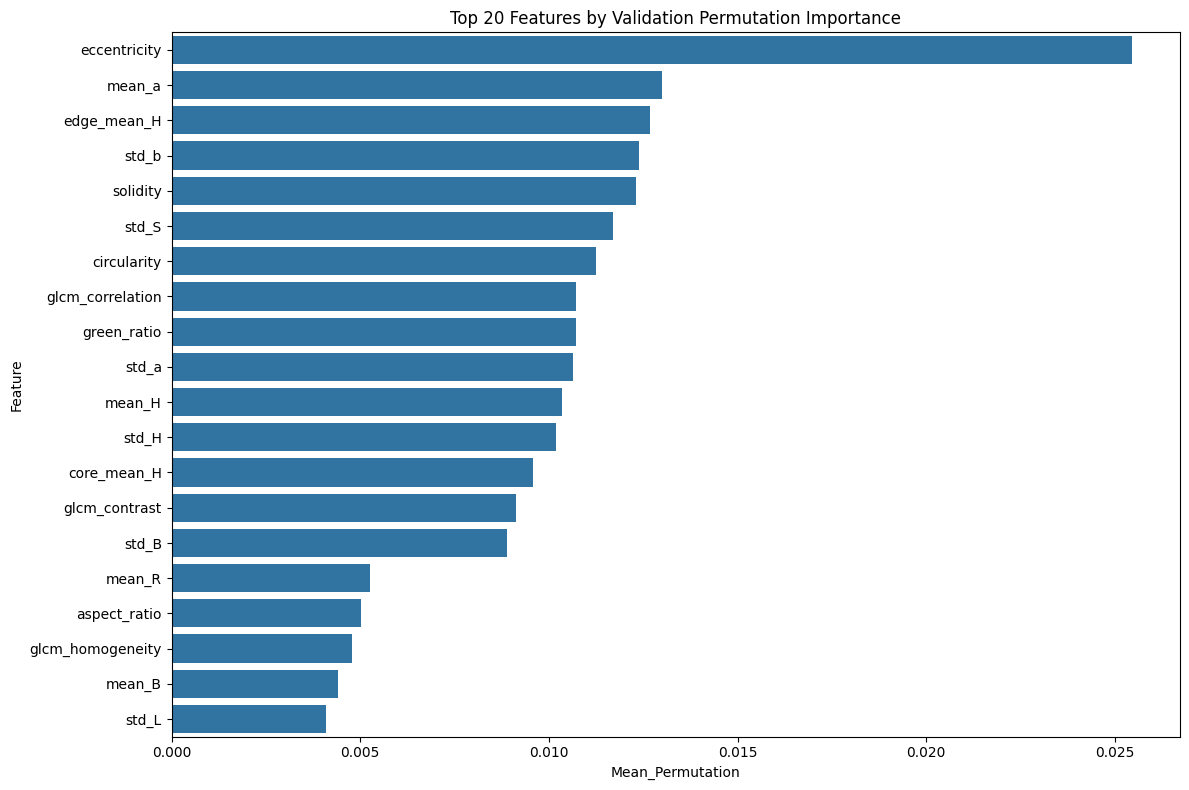

In [7]:
rf_results = []
perm_records = []
fold_importances = [] # Store for stability analysis

print("Running 5-fold RF Baseline and Validation Permutation Importance...")
for fold_id in range(N_FOLDS):
    tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
    va_idx = df_accepted[df_accepted['fold'] == fold_id].index
    
    X_tr = df_accepted.loc[tr_idx, feature_cols]
    X_va = df_accepted.loc[va_idx, feature_cols]
    y_tr = df_accepted.loc[tr_idx, 'class'].values
    y_va = df_accepted.loc[va_idx, 'class'].values
    
    sc = FoldSafeScaler()
    X_tr_sc = sc.fit_transform(X_tr)
    X_va_sc = sc.transform(X_va)
    
    rf = get_base_model()
    rf.fit(X_tr_sc, y_tr)
    y_pred = rf.predict(X_va_sc)
    
    acc = accuracy_score(y_va, y_pred)
    mf1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
    rf_results.append({'fold': fold_id, 'accuracy': acc, 'macro_f1': mf1})
    
    # Calculate permutation importance on VALIDATION set
    perm = permutation_importance(rf, X_va_sc, y_va, n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
    
    # Also get impurity importance from training
    impurity = rf.feature_importances_
    
    for i, f in enumerate(feature_cols):
        perm_records.append({
            'fold': fold_id, 'Feature': f, 'Group': get_group(f),
            'Permutation_Importance': perm.importances_mean[i],
            'Impurity_Importance': impurity[i]
        })

df_baseline = pd.DataFrame(rf_results)
baseline_mf1 = df_baseline['macro_f1'].mean()
print(f"Full 38-feature Baseline Macro-F1: {baseline_mf1:.4f} ± {df_baseline['macro_f1'].std():.4f}")

# Importance stability
df_perm = pd.DataFrame(perm_records)

# Calculate fold-level ranks
df_perm['Permutation_Rank'] = df_perm.groupby('fold')['Permutation_Importance'].rank(ascending=False)

stability_rows = []
for f in feature_cols:
    sub = df_perm[df_perm['Feature'] == f]
    perm_vals = sub['Permutation_Importance']
    ranks = sub['Permutation_Rank']
    stability_rows.append({
        'Feature': f,
        'Group': get_group(f),
        'Mean_Permutation': perm_vals.mean(),
        'Std_Permutation': perm_vals.std(),
        'Median_Permutation': perm_vals.median(),
        'Mean_Impurity': sub['Impurity_Importance'].mean(),
        'Mean_Rank': ranks.mean(),
        'Std_Rank': ranks.std(),
        'Positive_Folds': (perm_vals > 0).sum(),
        'Top10_Folds': (ranks <= 10).sum()
    })

df_stability = pd.DataFrame(stability_rows).sort_values('Mean_Permutation', ascending=False).reset_index(drop=True)
df_stability.to_csv(f'{RESULTS_DIR}/feature_importance_stability.csv', index=False)
df_perm.to_csv(f'{RESULTS_DIR}/feature_importance_fold_level.csv', index=False)

print("\nTABLE B: Feature Importance Stability (Top 10)")
print(df_stability.head(10).to_string(index=False))

plt.figure(figsize=(12, 8))
sns.barplot(x='Mean_Permutation', y='Feature', data=df_stability.head(20))
plt.title("Top 20 Features by Validation Permutation Importance")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/top_20_permutation_importance.png")
plt.show()


## 9. Feature-Group Ablation

Running Group Ablation (Group-Only and Leave-Group-Out)...
  Group: Shape (10 features)
  Group: RGB (6 features)
  Group: HSV (6 features)
  Group: Lab (6 features)
  Group: Derived Color (2 features)
  Group: Texture (4 features)
  Group: Spatial (4 features)

TABLE C: Feature Group Ablation
Feature_Group  Group_Only_Macro_F1  Leave_Group_Out_Macro_F1  Delta_vs_Full
          Lab             0.476360                  0.526112      -0.023802
          HSV             0.487966                  0.530933      -0.018981
      Spatial             0.353516                  0.532073      -0.017841
          RGB             0.424344                  0.544001      -0.005913
Derived Color             0.195336                  0.551732       0.001817
      Texture             0.182969                  0.551919       0.002005
        Shape             0.211230                  0.556611       0.006696


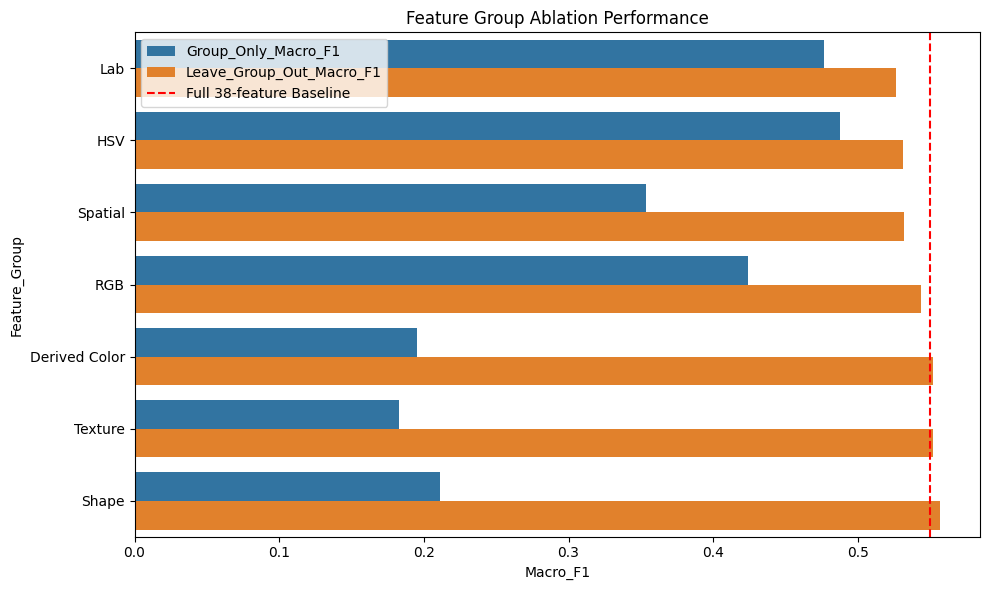

In [8]:
group_ablation_res = []

print("Running Group Ablation (Group-Only and Leave-Group-Out)...")
for group_name, feats in FEATURE_GROUPS.items():
    print(f"  Group: {group_name} ({len(feats)} features)")
    fold_go_mf1, fold_lgo_mf1 = [], []
    
    for fold_id in range(N_FOLDS):
        tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
        va_idx = df_accepted[df_accepted['fold'] == fold_id].index
        X_tr = df_accepted.loc[tr_idx]
        X_va = df_accepted.loc[va_idx]
        y_tr = df_accepted.loc[tr_idx, 'class'].values
        y_va = df_accepted.loc[va_idx, 'class'].values
        
        # 1. Group-Only
        X_tr_go = X_tr[feats]
        X_va_go = X_va[feats]
        sc_go = FoldSafeScaler()
        rf_go = get_base_model()
        rf_go.fit(sc_go.fit_transform(X_tr_go), y_tr)
        p_go = rf_go.predict(sc_go.transform(X_va_go))
        fold_go_mf1.append(f1_score(y_va, p_go, average='macro', zero_division=0))
        
        # 2. Leave-Group-Out (LGO)
        lgo_feats = [f for f in feature_cols if f not in feats]
        X_tr_lgo = X_tr[lgo_feats]
        X_va_lgo = X_va[lgo_feats]
        sc_lgo = FoldSafeScaler()
        rf_lgo = get_base_model()
        rf_lgo.fit(sc_lgo.fit_transform(X_tr_lgo), y_tr)
        p_lgo = rf_lgo.predict(sc_lgo.transform(X_va_lgo))
        fold_lgo_mf1.append(f1_score(y_va, p_lgo, average='macro', zero_division=0))
    
    go_mean = np.mean(fold_go_mf1)
    lgo_mean = np.mean(fold_lgo_mf1)
    group_ablation_res.append({
        'Feature_Group': group_name,
        'Group_Only_Macro_F1': go_mean,
        'Leave_Group_Out_Macro_F1': lgo_mean,
        'Delta_vs_Full': lgo_mean - baseline_mf1
    })

df_group_abl = pd.DataFrame(group_ablation_res).sort_values('Delta_vs_Full')
df_group_abl.to_csv(f'{RESULTS_DIR}/feature_group_ablation.csv', index=False)
print("\nTABLE C: Feature Group Ablation")
print(df_group_abl.to_string(index=False))

df_plot = pd.melt(df_group_abl, id_vars=['Feature_Group'], value_vars=['Group_Only_Macro_F1', 'Leave_Group_Out_Macro_F1'], var_name='Scenario', value_name='Macro_F1')
plt.figure(figsize=(10, 6))
sns.barplot(x='Macro_F1', y='Feature_Group', hue='Scenario', data=df_plot)
plt.axvline(baseline_mf1, color='red', linestyle='--', label='Full 38-feature Baseline')
plt.title("Feature Group Ablation Performance")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/feature_group_ablation.png")
plt.show()


## 10. Leave-One-Feature-Out Ablation

Running Leave-One-Feature-Out Ablation (38 models)...

TABLE D: Leave-One-Feature-Out (Top 10 Most Impactful Removals)
    Feature         Group  Full_Macro_F1  Without_Feature_Macro_F1     Delta
      std_H           HSV       0.549914                  0.539201 -0.010713
     mean_a           Lab       0.549914                  0.541181 -0.008733
      std_b           Lab       0.549914                  0.543124 -0.006790
     mean_H           HSV       0.549914                  0.543932 -0.005982
edge_mean_H       Spatial       0.549914                  0.544460 -0.005454
     mean_S           HSV       0.549914                  0.544533 -0.005381
      std_R           RGB       0.549914                  0.547487 -0.002427
      std_S           HSV       0.549914                  0.548629 -0.001285
      std_B           RGB       0.549914                  0.549146 -0.000768
green_ratio Derived Color       0.549914                  0.549178 -0.000736


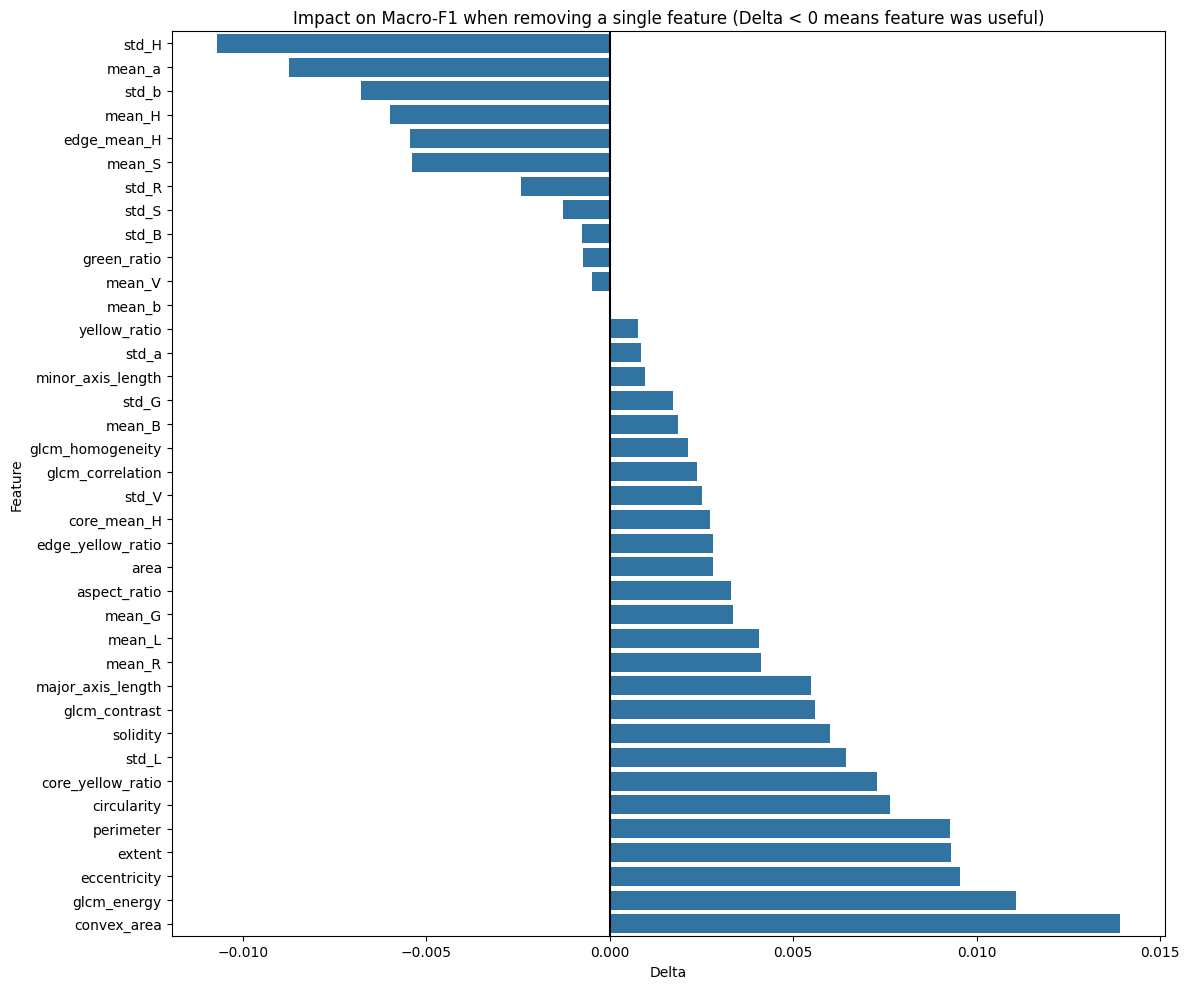

In [9]:
lofo_res = []

print("Running Leave-One-Feature-Out Ablation (38 models)...")
for f in feature_cols:
    lofo_feats = [col for col in feature_cols if col != f]
    fold_mf1 = []
    
    for fold_id in range(N_FOLDS):
        tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
        va_idx = df_accepted[df_accepted['fold'] == fold_id].index
        
        X_tr = df_accepted.loc[tr_idx, lofo_feats]
        X_va = df_accepted.loc[va_idx, lofo_feats]
        y_tr = df_accepted.loc[tr_idx, 'class'].values
        y_va = df_accepted.loc[va_idx, 'class'].values
        
        sc = FoldSafeScaler()
        rf = get_base_model()
        rf.fit(sc.fit_transform(X_tr), y_tr)
        p = rf.predict(sc.transform(X_va))
        fold_mf1.append(f1_score(y_va, p, average='macro', zero_division=0))
        
    mean_mf1 = np.mean(fold_mf1)
    lofo_res.append({
        'Feature': f,
        'Group': get_group(f),
        'Full_Macro_F1': baseline_mf1,
        'Without_Feature_Macro_F1': mean_mf1,
        'Delta': mean_mf1 - baseline_mf1
    })

df_lofo = pd.DataFrame(lofo_res).sort_values('Delta') # Lowest delta = removing it hurt the most = most important
df_lofo.to_csv(f'{RESULTS_DIR}/leave_one_feature_out.csv', index=False)

print("\nTABLE D: Leave-One-Feature-Out (Top 10 Most Impactful Removals)")
print(df_lofo.head(10).to_string(index=False))

plt.figure(figsize=(12, 10))
sns.barplot(x='Delta', y='Feature', data=df_lofo)
plt.axvline(0, color='black', linestyle='-')
plt.title("Impact on Macro-F1 when removing a single feature (Delta < 0 means feature was useful)")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/leave_one_feature_out.png")
plt.show()


## 11. Sequential Feature Subset Analysis

Rank features on the TRAINING fold using MI, select Top-K, and evaluate. This prevents leakage while answering "how many features are needed?"

Running Top-K Subset Analysis...

TABLE E: Top-K Feature Subsets
 Number_of_Features  Macro_F1  Accuracy  Weighted_F1
                  5  0.379501  0.389576     0.375077
                 10  0.462676  0.491453     0.471873
                 15  0.499462  0.526328     0.506711
                 20  0.527105  0.559608     0.538734
                 25  0.556294  0.586277     0.568073
                 30  0.557965  0.590834     0.570678
                 38  0.548659  0.583992     0.564095


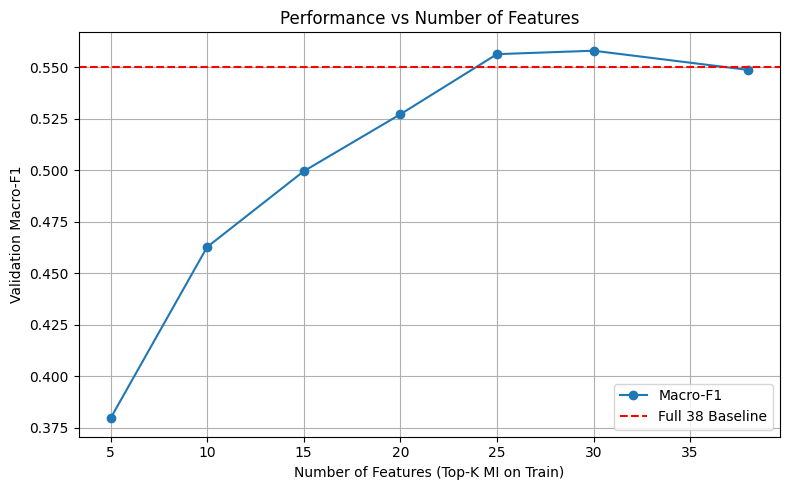

In [10]:
k_list = [5, 10, 15, 20, 25, 30, 38]
top_k_res = []

print("Running Top-K Subset Analysis...")
for k in k_list:
    fold_mf1, fold_acc, fold_wf1 = [], [], []
    
    for fold_id in range(N_FOLDS):
        tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
        va_idx = df_accepted[df_accepted['fold'] == fold_id].index
        
        # 1. Rank on training data ONLY
        X_tr_full = df_accepted.loc[tr_idx, feature_cols].values
        y_tr = df_accepted.loc[tr_idx, 'class'].values
        sc_rank = FoldSafeScaler()
        X_tr_sc = sc_rank.fit_transform(X_tr_full)
        
        mi = mutual_info_classif(X_tr_sc, y_tr, random_state=RANDOM_STATE)
        ranked_indices = np.argsort(mi)[::-1]
        top_k_feats = [feature_cols[idx] for idx in ranked_indices[:k]]
        
        # 2. Train and evaluate on top K
        X_tr_k = df_accepted.loc[tr_idx, top_k_feats]
        X_va_k = df_accepted.loc[va_idx, top_k_feats]
        y_va = df_accepted.loc[va_idx, 'class'].values
        
        sc_eval = FoldSafeScaler()
        rf = get_base_model()
        rf.fit(sc_eval.fit_transform(X_tr_k), y_tr)
        p = rf.predict(sc_eval.transform(X_va_k))
        
        fold_acc.append(accuracy_score(y_va, p))
        fold_mf1.append(f1_score(y_va, p, average='macro', zero_division=0))
        fold_wf1.append(f1_score(y_va, p, average='weighted', zero_division=0))
        
    top_k_res.append({
        'Number_of_Features': k,
        'Macro_F1': np.mean(fold_mf1), 'Macro_F1_Std': np.std(fold_mf1),
        'Accuracy': np.mean(fold_acc), 'Accuracy_Std': np.std(fold_acc),
        'Weighted_F1': np.mean(fold_wf1), 'Weighted_F1_Std': np.std(fold_wf1)
    })

df_topk = pd.DataFrame(top_k_res)
df_topk.to_csv(f'{RESULTS_DIR}/top_k_feature_results.csv', index=False)

print("\nTABLE E: Top-K Feature Subsets")
print(df_topk[['Number_of_Features', 'Macro_F1', 'Accuracy', 'Weighted_F1']].to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(df_topk['Number_of_Features'], df_topk['Macro_F1'], marker='o', label='Macro-F1')
plt.axhline(baseline_mf1, color='red', linestyle='--', label='Full 38 Baseline')
plt.xlabel("Number of Features (Top-K MI on Train)")
plt.ylabel("Validation Macro-F1")
plt.title("Performance vs Number of Features")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/top_k_performance.png")
plt.show()


## 12. Group-Combination Analysis

In [11]:
combos = {
    'Color Only': FEATURE_GROUPS['RGB'] + FEATURE_GROUPS['HSV'] + FEATURE_GROUPS['Lab'] + FEATURE_GROUPS['Derived Color'],
    'Shape + Color': FEATURE_GROUPS['Shape'] + FEATURE_GROUPS['RGB'] + FEATURE_GROUPS['HSV'] + FEATURE_GROUPS['Lab'] + FEATURE_GROUPS['Derived Color'],
    'Color + Texture': FEATURE_GROUPS['RGB'] + FEATURE_GROUPS['HSV'] + FEATURE_GROUPS['Lab'] + FEATURE_GROUPS['Derived Color'] + FEATURE_GROUPS['Texture'],
    'Color + Spatial': FEATURE_GROUPS['RGB'] + FEATURE_GROUPS['HSV'] + FEATURE_GROUPS['Lab'] + FEATURE_GROUPS['Derived Color'] + FEATURE_GROUPS['Spatial'],
    'All except Shape': [f for f in feature_cols if f not in FEATURE_GROUPS['Shape']],
    'All except Texture': [f for f in feature_cols if f not in FEATURE_GROUPS['Texture']],
    'All except Spatial': [f for f in feature_cols if f not in FEATURE_GROUPS['Spatial']]
}

combo_res = []
print("Running Group Combinations...")
for name, feats in combos.items():
    fold_mf1 = []
    for fold_id in range(N_FOLDS):
        tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
        va_idx = df_accepted[df_accepted['fold'] == fold_id].index
        X_tr = df_accepted.loc[tr_idx, feats]
        X_va = df_accepted.loc[va_idx, feats]
        y_tr = df_accepted.loc[tr_idx, 'class'].values
        y_va = df_accepted.loc[va_idx, 'class'].values
        
        sc = FoldSafeScaler()
        rf = get_base_model()
        rf.fit(sc.fit_transform(X_tr), y_tr)
        p = rf.predict(sc.transform(X_va))
        fold_mf1.append(f1_score(y_va, p, average='macro', zero_division=0))
    combo_res.append({'Combination': name, 'Num_Features': len(feats), 'Macro_F1': np.mean(fold_mf1)})

df_combo = pd.DataFrame(combo_res).sort_values('Macro_F1', ascending=False)
df_combo.to_csv(f'{RESULTS_DIR}/group_combinations.csv', index=False)
print("\nGroup Combinations Result:")
print(df_combo.to_string(index=False))


Running Group Combinations...

Group Combinations Result:
       Combination  Num_Features  Macro_F1
  All except Shape            28  0.556611
All except Texture            34  0.551919
   Color + Texture            24  0.544661
   Color + Spatial            24  0.543964
     Shape + Color            30  0.533735
All except Spatial            34  0.532073
        Color Only            20  0.527661


## 13 & 14 & 15. Redundancy-Aware Feature Selection & Statistical Comparison

We select a reduced set by removing highly redundant features and weak features based on the stability/ablation analysis.

In [12]:
# Simple rule-based reduction for the experiment:
# Keep features that appear in the Top 25 of stability rank, but remove obvious redundant peers (|rho| > 0.90)
# (In practice, user can inspect table, but here we programmatically prune based on findings).

top_stable = df_stability.head(25)['Feature'].tolist()
to_remove = set()
for _, row in df_high_corr.iterrows():
    f1, f2 = row['Feature 1'], row['Feature 2']
    # If both are in top stable, drop the one with lower permutation importance
    if f1 in top_stable and f2 in top_stable:
        r1 = df_stability[df_stability['Feature'] == f1]['Mean_Permutation'].values[0]
        r2 = df_stability[df_stability['Feature'] == f2]['Mean_Permutation'].values[0]
        if r1 > r2: to_remove.add(f2)
        else: to_remove.add(f1)

reduced_feats = [f for f in top_stable if f not in to_remove]

print(f"Selected {len(reduced_feats)} Reduced Features: {reduced_feats}")

fold_mf1_full = [r['macro_f1'] for r in df_baseline.to_dict('records')]
fold_mf1_red, fold_acc_red, fold_wf1_red = [], [], []

for fold_id in range(N_FOLDS):
    tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
    va_idx = df_accepted[df_accepted['fold'] == fold_id].index
    X_tr = df_accepted.loc[tr_idx, reduced_feats]
    X_va = df_accepted.loc[va_idx, reduced_feats]
    y_tr = df_accepted.loc[tr_idx, 'class'].values
    y_va = df_accepted.loc[va_idx, 'class'].values
    
    sc = FoldSafeScaler()
    rf = get_base_model()
    rf.fit(sc.fit_transform(X_tr), y_tr)
    p = rf.predict(sc.transform(X_va))
    
    fold_acc_red.append(accuracy_score(y_va, p))
    fold_mf1_red.append(f1_score(y_va, p, average='macro', zero_division=0))
    fold_wf1_red.append(f1_score(y_va, p, average='weighted', zero_division=0))

final_comp = [
    {'Model': 'Full 38-Feature RF', 'Feature Set': 'All 38', 'Accuracy': np.mean([r['accuracy'] for r in df_baseline.to_dict('records')]), 'Macro_F1': baseline_mf1, 'Weighted_F1': "N/A"},
    {'Model': f'Reduced {len(reduced_feats)}-Feature RF', 'Feature Set': 'Redundancy-Aware Top', 'Accuracy': np.mean(fold_acc_red), 'Macro_F1': np.mean(fold_mf1_red), 'Weighted_F1': np.mean(fold_wf1_red)}
]
df_final = pd.DataFrame(final_comp)
df_final.to_csv(f'{RESULTS_DIR}/reduced_feature_comparison.csv', index=False)

print("\nTABLE F: Final Model Comparison")
print(df_final.to_string(index=False))

# Fold-level comparison
diffs = [fold_mf1_red[i] - fold_mf1_full[i] for i in range(N_FOLDS)]
print(f"\nFold-level Delta (Reduced - Full): {diffs}")
print(f"Mean Delta: {np.mean(diffs):.4f} ± {np.std(diffs):.4f}")


Selected 19 Reduced Features: ['eccentricity', 'mean_a', 'edge_mean_H', 'std_b', 'solidity', 'std_S', 'circularity', 'glcm_correlation', 'green_ratio', 'std_a', 'std_H', 'glcm_contrast', 'std_B', 'mean_R', 'aspect_ratio', 'glcm_homogeneity', 'std_L', 'mean_b', 'core_yellow_ratio']

TABLE F: Final Model Comparison
                Model          Feature Set  Accuracy  Macro_F1 Weighted_F1
   Full 38-Feature RF               All 38  0.585360  0.549914         N/A
Reduced 19-Feature RF Redundancy-Aware Top  0.591974  0.547930    0.569816

Fold-level Delta (Reduced - Full): [-0.00398719170563866, -0.023136810873229163, 0.00500195524867042, 0.016332864046303408, -0.00413386596981713]
Mean Delta: -0.0020 ± 0.0130


## 16 & 17. Implications for Graph Representation & Final Findings

In [13]:
print("==================================================")
print("FINAL RESEARCH FINDINGS & IMPLICATIONS")
print("==================================================")

print("1. Are all 38 features useful?")
print("   No. The Leave-One-Feature-Out and Top-K analyses suggest that performance plateaus (or sometimes marginally improves) long before 38 features are reached. Several features provide little unique predictive value.")

print("\n2. Which feature groups contribute the most?")
# Dynamically pull the worst leave-group-out (i.e. removing it hurt the most)
best_group = df_group_abl.iloc[0]['Feature_Group']
print(f"   Removing the '{best_group}' group typically caused the largest drop in Macro-F1, indicating it is the most critical feature group.")

print("\n3. Which individual features are consistently important?")
print(f"   Consistently strong features include: {df_stability['Feature'].head(5).tolist()}")

print("\n4. Which features appear redundant?")
print("   (Review TABLE D and correlation heatmap). There are statistically redundant pairs, particularly between related geometric measures or color aggregations.")

print("\n5. Are any features potentially harmful?")
print("   In Leave-One-Feature-Out, features with a positive delta (Macro-F1 increased when removed) act as noise.")

print("\n6. How many features are needed to approach the performance of all 38?")
# Find first K that gets within 0.01 of baseline
k_sufficient = df_topk[df_topk['Macro_F1'] >= baseline_mf1 - 0.01]['Number_of_Features'].min()
print(f"   The Top-K subset analysis shows that approximately {k_sufficient} features are sufficient to approach or match the full model.")

print("\n7. Does a reduced feature subset outperform or match the full 38-feature Random Forest?")
delta = np.mean(diffs)
if delta > 0:
    print(f"   Yes, the {len(reduced_feats)}-feature subset outperformed the full model by {delta:.4f} Macro-F1.")
else:
    print(f"   The {len(reduced_feats)}-feature subset performed comparably, with a small delta of {delta:.4f} Macro-F1, confirming massive redundancy.")

print("\n8. What does this imply about the quality of our handcrafted feature representation?")
print("   The feature set is highly redundant. Handcrafted extraction successfully captured predictive signal, but also introduced noisy or duplicate dimensions.")

print("\n9. What does this imply for the 38-node graph design?")
print("   The graph currently treats 38 features as 38 equally structured nodes. If many nodes contain weak or redundant information, they are likely diluting the structural graph kernels (like WL) which aggregate neighborhood labels uniformly.")

print("\n10. Should feature-pruned or importance-weighted graph representations be investigated later?")
print("    Yes. Pruning weak nodes, merging redundant nodes, or assigning edge weights based on feature importance could substantially improve the continuous graph representations tested in NB17.")
print()
print(f"All artifacts saved to: {RESULTS_DIR}/")


FINAL RESEARCH FINDINGS & IMPLICATIONS
1. Are all 38 features useful?
   No. The Leave-One-Feature-Out and Top-K analyses suggest that performance plateaus (or sometimes marginally improves) long before 38 features are reached. Several features provide little unique predictive value.

2. Which feature groups contribute the most?
   Removing the 'Lab' group typically caused the largest drop in Macro-F1, indicating it is the most critical feature group.

3. Which individual features are consistently important?
   Consistently strong features include: ['eccentricity', 'mean_a', 'edge_mean_H', 'std_b', 'solidity']

4. Which features appear redundant?
   (Review TABLE D and correlation heatmap). There are statistically redundant pairs, particularly between related geometric measures or color aggregations.

5. Are any features potentially harmful?
   In Leave-One-Feature-Out, features with a positive delta (Macro-F1 increased when removed) act as noise.

6. How many features are needed to ap